# 11 领取优惠券的优化

## 本章范围与资料来源

第 10 章解决单 JVM 内的库存超发、用户超领和事务边界。本章继续处理多实例部署与高并发：用分布式锁实现跨 JVM 互斥，再把领取资格校验放到 Redis、入库操作交给 MQ，最后用 Lua 将多次 Redis 校验与预占合成一次调用。

| 来源 | 本章实际使用的内容 |
| --- | --- |
| [网盘分享](https://pan.baidu.com/s/1dcVvDI-sWN68Xzcsz1LSAQ?pwd=w7bj)，提取码 `w7bj` | `day11-领取优惠券的优化/讲义/day11-领取优惠券优化.pptx`，共 49 页；核对分布式锁、异步领券、兑换码练习、Lua 及 MQ 规范；内嵌第 30、44 页原图 |
| 网盘 `day11-领取优惠券的优化/资料` | 确认有 `exchange_coupon.lua`、`receive_coupon.lua`、`UserCouponDTO.java`、`领取优惠券.jmx`；Lua 预览未取得正文，这些独立附件未作为已读源码 |
| [第三方公开转载：Day11-领取优惠券的优化](https://imousse.github.io/cswiki/src/project/college/11-%E4%BC%98%E6%83%A0%E5%88%B8%E4%BC%98%E5%8C%96) | 补充 Redisson、AOP、工厂、策略、SpEL、缓存生命周期、MQ 消费与兑换脚本；内嵌集群锁失效的讲义原图 |

阅读日期：2026-10-09。**课件方案**指材料明确展示的做法；**整理示例**是按材料重写的教学片段；**补充 / 改进示例**用于修正时间单位、幂等、补偿和集群边界。Java 示例遵循 Java 11；省略类、导包与依赖的片段用于解释流程。本 Notebook 全部为 Markdown，不运行课程服务、数据库、Redis、MQ 或 JMeter。

## 先区分库存超发与用户超领

券库存只有 100 张却发了 101 张，与用户限领 1 张却领了 2 张，是两个不同约束。

| 约束 | 共享数据 | 第 10 章方案 | 本章改造 |
| --- | --- | --- | --- |
| 全局发放数量不能超过总数量 | `coupon.issue_num` 与 `total_num` | 条件更新 `issue_num < total_num` | Redis 原子预占，数据库条件更新继续兜底 |
| 用户累计领取数量不能超过 `user_limit` | 同一个用户与模板的领取次数 | 本机锁覆盖查询、判断、新增及事务提交 | 跨实例锁，或 Lua 校验并增加计数 |
| 同一兑换码只能兑现一次 | Bitmap 和兑换码记录 | `SETBIT` 占用 + 数据库状态更新 | Redis 原子资格校验 + 消费端条件更新 |

限领统计包括已使用、已过期的领取记录；“当前可用券数”是另一个查询口径。异步化后，计数还要包括已受理、尚未入库的请求，否则消费延迟期间会漏算。

本章改变处理方式，用户端入口仍是 `POST /user-coupons/{id}/receive` 和 `POST /user-coupons/{code}/exchange`。

## 多实例部署为什么让本机锁失效

`synchronized(userId.toString().intern())` 在同一个 JVM 内能让相同用户竞争同一个监视器；两个 JVM 各有自己的对象和常量池，即使用户 ID 相同，也不是同一把锁。两个实例可以同时通过限领判断。

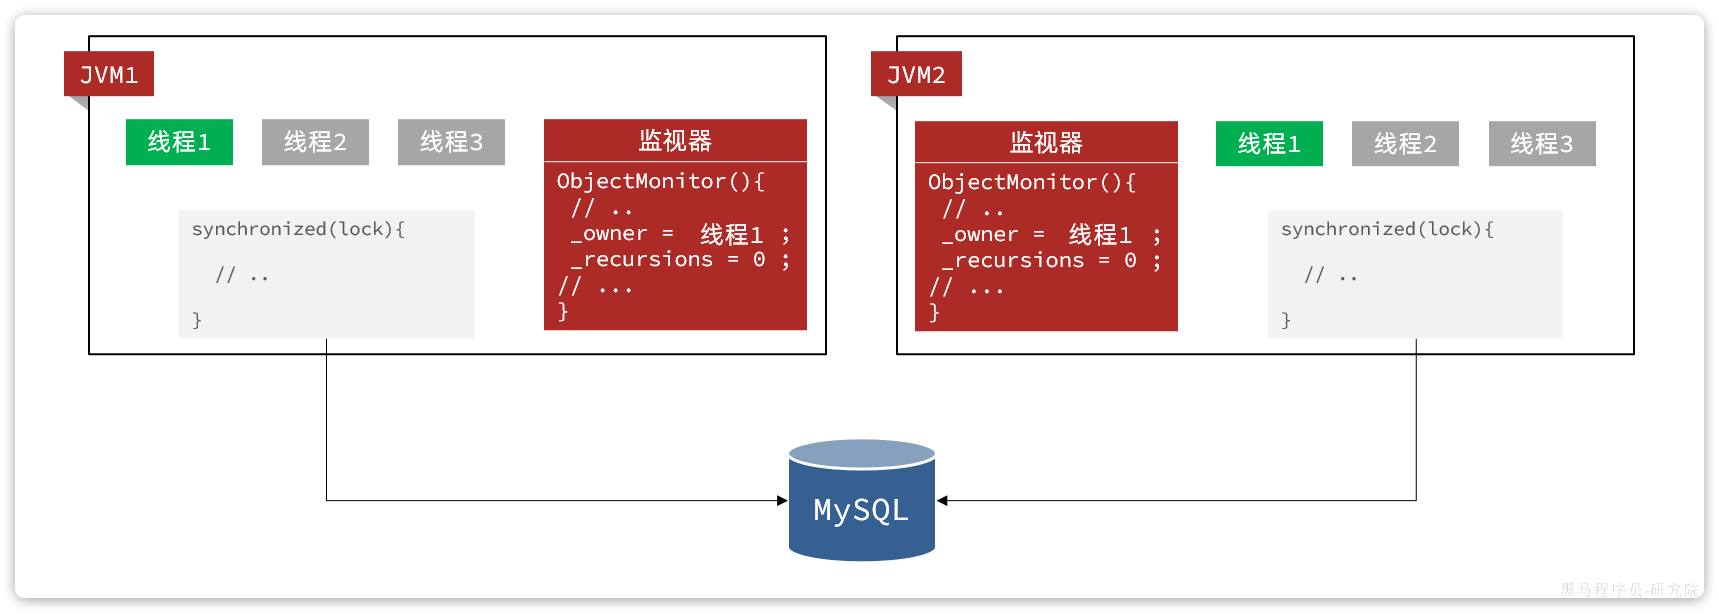

分布式锁把互斥状态放到多个实例都能访问的外部组件。锁的本质仍是“同一资源同一时刻只有一个持有者”，变化的是锁状态的存放位置。

| 实现 | 互斥范围 | 适用判断 |
| --- | --- | --- |
| `synchronized` / `ReentrantLock` | 单 JVM | 本进程共享内存 |
| Redis / Redisson | 访问同一 Redis 锁键的实例 | 临界区短、性能要求较高 |
| MySQL 行锁 / 唯一约束 | 同一数据库 | 与持久化事务一起维护强业务约束 |
| ZooKeeper / etcd | 访问同一协调集群的实例 | 协调、租约等场景，成本更高 |

Monitor 是课件解释重量级 `synchronized` 的模型；JVM 也有其他优化实现。无论具体优化如何，本机锁都不能跨 JVM。

## 简单 Redis 锁：获取锁和设置租约必须一起完成

Redis 的 `SETNX` 只在 key 不存在时成功，能实现争抢互斥；实例宕机后还要自动释放，否则会永久占用。

```text
# 错误拆分：第一条成功后宕机，第二条永远不会执行
SETNX lock:coupon:user:42 token-A
EXPIRE lock:coupon:user:42 10

# 一条命令原子设置值、互斥条件、租约
SET lock:coupon:user:42 token-A NX EX 10
```

`NX` 表示不存在才写入，`EX` 的单位是秒，`PX` 的单位是毫秒。获取成功返回 `OK`，争抢失败返回空；Spring Data Redis 对应带超时的 `setIfAbsent`。

```java
String token = UUID.randomUUID().toString(); // 每次获取生成独立标识
Boolean acquired = redisTemplate.opsForValue()
        .setIfAbsent(key, token, 10, TimeUnit.SECONDS);
if (!Boolean.TRUE.equals(acquired)) {
    throw new BizIllegalException("请求太频繁");
}
```

**课件方案**先演示“尝试一次，失败立即返回”的非阻塞锁；是否等待与重试是后续策略。获取锁失败不能继续执行业务。

## 唯一持有者标识和原子解锁

线程 A 拿锁后暂停，租约到期；线程 B 拿到同一 key；A 恢复后直接 `DEL key`，就会误删 B 的锁。只用线程名也不足以识别持有者：不同进程有同名线程，同一线程也会多次请求。

即使先 `GET` 判断标识再 `DEL`，两条命令之间也可能发生超时和重新加锁。**补充 / 改进示例**：用唯一 token 识别本次持有者，用 Lua 一次完成校验和删除。

```lua
-- KEYS[1]：锁键；ARGV[1]：本次加锁 token
if redis.call('GET', KEYS[1]) == ARGV[1] then
    return redis.call('DEL', KEYS[1])
end
return 0
```

```java
try {
    // 调用独立 Bean 的事务方法，等待提交或回滚完成
    issueTxService.create(couponId, userId);
} finally {
    redisTemplate.execute(UNLOCK_SCRIPT,
            Collections.singletonList(key), token);
}
```

这里的解锁只删除自己仍持有的锁，不能阻止已失去租约的旧线程继续写数据库。后者属于租约失效后的写入防护问题，仍需数据库约束等兜底。

## 简单锁还缺少什么能力

“SET 加锁 + Lua 解锁”只解决基本互斥和误删，完整分布式锁还需要管理生命周期。

| 问题 | 原因 | 课件对应机制 | 实际边界 |
| --- | --- | --- | --- |
| 不可重入 | 同线程再次获取被自己占用的 key | Hash 记录持有者与重入次数 | 获取加 1，解锁减 1，减到 0 才删除 |
| 长任务超过租约 | 固定超时时间不足 | Watchdog 定期续期 | 客户端停顿、网络分区仍可能续期失败 |
| 争抢失败 | 当前有持有者 | 等待、重试，结合 Pub/Sub 通知 | 超时、取消和中断要有明确结果 |
| 主从切换丢锁 | 异步复制未同步锁状态 | 课件介绍 RedLock | 普通 RLock 不自动变成 RedLock；两者都需评估故障假设 |

RedLock 基于多个独立 Redis 节点争取多数成功，不能简单理解成“Redis 主从锁的绝对一致性修复”。强业务不变量应由数据库条件、唯一约束或持久化状态保障。

**面试提示**：自动过期解决宕机占用；唯一 token + 原子解锁解决误删；续期减少提前过期。不要把三个问题混成一句“加了 TTL 就安全”。

## Redisson 集成与安全使用

Redisson 把 Redis 上的锁、队列、集合等包装成 Java API，本章使用 `RedissonClient` 与 `RLock`。课件展示 `redisson:3.13.6` 入门，项目已有统一配置，应按项目依赖管理选择版本。

```xml
<dependency>
    <groupId>org.redisson</groupId>
    <artifactId>redisson</artifactId>
</dependency>
```

天机学堂 `tj-common` 的 Redis 配置通过条件注解按需创建 RedissonClient，并复用 Spring Boot 的单机、哨兵或集群配置。已有统一配置时不要再创建第二个客户端；自定义 Bean 时要管理关闭生命周期。课件 `setPassowrd` 是笔误，实际 API 为 `setPassword`，地址及密码从配置读取。

**整理示例**：锁外不开启数据库事务，拿锁后调用独立事务 Bean。

```java
public void receive(Long couponId, Long userId) {
    RLock lock = redissonClient.getLock("lock:coupon:user:" + userId);
    boolean acquired = false;
    try {
        acquired = lock.tryLock(1, TimeUnit.SECONDS); // 使用自动续期模式
        if (!acquired) throw new BizIllegalException("请求太频繁");
        issueTxService.checkAndCreate(couponId, userId); // 代理返回后事务已结束
    } catch (InterruptedException e) {
        Thread.currentThread().interrupt();
        throw new BizIllegalException("等待领券被中断");
    } finally {
        if (acquired && lock.isHeldByCurrentThread()) lock.unlock();
    }
}
```

课件入门片段在未拿到锁时也执行 `unlock()`，直接照搬会抛异常；必须只解锁已取得的锁。`isHeldByCurrentThread()` 是持有者检查，不能证明业务执行期间租约从未丢失。

## waitTime、leaseTime 和 Watchdog 的区别

等锁多久和拿到后能持有多久是两件事。

| 调用 | 等待策略 | 持有策略 |
| --- | --- | --- |
| `tryLock()` | 不等待，立即返回布尔值 | 未指定固定租约，走 watchdog |
| `tryLock(1, SECONDS)` | 最多等待 1 秒 | watchdog 续期 |
| `tryLock(1, 10, SECONDS)` | 最多等待 1 秒 | 显式 10 秒租约，通常不启用 watchdog |
| `lock()` | 持续等待直到获取 | watchdog 续期 |
| `lock(10, SECONDS)` | 持续等待直到获取 | 固定 10 秒租约 |

Watchdog 在客户端正常存活并保持锁所有权时续期；默认超时配置常见为 30 秒，实际以 Redisson 版本及 `lockWatchdogTimeout` 配置为准。不要把“默认 30 秒”理解成无条件 30 秒后释放，也不要把 `lock()` 理解成不等待。

需要响应中断的后台等待可采用 `lockInterruptibly()`。固定租约要覆盖业务耗时，但把租约无限增大又会放大宕机恢复时间。

## 锁的粒度必须匹配共享资源

选错锁键比选错锁 API 更常见。同一个临界区的所有入口必须按同一规则取锁。

| 场景 | 应互斥的资源 | 适合的键 |
| --- | --- | --- |
| 数据库判断某用户限领 | 用户与券的累计领取 | `lock:coupon:{couponId}:user:{userId}`，或范围更宽的用户锁 |
| Java 多条 Redis 命令判断库存并扣减 | 同一张券的全局余量 | `lock:coupon:{couponId}` |
| Lua 资格校验 | 同一 Redis 节点上脚本访问的数据 | 短脚本内完成，不再另加同范围锁 |

**课件方案**异步手动领券用 `@Lock(name = "lock:coupon:#{couponId}")`，因为库存校验与扣减是多条命令。若改为只锁 userId，不同用户能同时看到最后一个库存，会导致 Redis 预占超发。

反过来，对整张券加锁也会让所有用户串行。Lua 把临界区放到 Redis 内后，省掉了“客户端等待锁 + 多次网络往返”，但热点券仍是共享热点，并不会无限扩展。

## 基于注解的锁：AOP 封装固定流程

每个业务都重复“创建锁、尝试获取、处理失败、finally 释放”会挤占业务代码。注解用于标记切入点、传入参数；AOP 环绕通知负责业务前后的锁操作。

**整理示例**：先保留基础可重入锁，工厂和策略在后续扩展。

```java
@Retention(RetentionPolicy.RUNTIME)
@Target(ElementType.METHOD)
public @interface MyLock {
    String name();
    long waitTime() default 1;
    long leaseTime() default -1;
    TimeUnit unit() default TimeUnit.SECONDS;
}
```

```java
@Around("@annotation(spec)")
public Object around(ProceedingJoinPoint pjp, MyLock spec) throws Throwable {
    RLock lock = redissonClient.getLock(resolveName(spec.name(), pjp));
    boolean acquired;
    try {
        acquired = spec.leaseTime() < 0
                ? lock.tryLock(spec.waitTime(), spec.unit())
                : lock.tryLock(spec.waitTime(), spec.leaseTime(), spec.unit());
    } catch (InterruptedException e) {
        Thread.currentThread().interrupt();
        throw e;
    }
    if (!acquired) throw new BizIllegalException("请求太频繁");
    try {
        return pjp.proceed();
    } finally {
        if (lock.isHeldByCurrentThread()) lock.unlock();
    }
}
```

切面类由 Spring 管理并标记 `@Aspect`；`resolveName` 是后文的动态锁名解析。最终项目已在 `tj-common` 封装 `@Lock`，教学用 `MyLock` 是展示实现过程，不必在业务模块重复造一套。

## 锁切面必须在事务切面外层

若事务先开始、锁先释放，下一请求可能读不到上一请求尚未提交的数据，限领仍会失效。

```text
正确：获取锁 -> 开启事务 -> 查询/更新/插入 -> 提交或回滚 -> 释放锁
错误：开启事务 -> 获取锁 -> 查询/更新/插入 -> 释放锁 -> 提交事务
```

**课件方案**锁切面实现 `Ordered` 并返回 `0`，事务切面通常默认 `Integer.MAX_VALUE`：order 更小的先进入，退出时顺序相反，所以事务先提交，锁后释放。

```java
@Override
public int getOrder() {
    return 0;
}
```

实际工程需核对自定义事务 advisor 的 order，不能只背默认值。使用独立事务 Bean 也能直接看清边界。两种方案都要求经 Spring 代理调用；同类 `this` 自调用可能同时绕过锁切面和事务切面。外层若已有事务，内层默认 `REQUIRED` 只加入外层，锁释放时也未必已提交，应禁止这类调用或重新设计入口。

**面试提示**：AOP 是代理增强，自调用失效与“锁释放早于事务提交”是两个不同问题，都要检查。

## 工厂模式选择锁类型

锁的创建方式不同，统一交给简单工厂；业务只声明锁类型。

| 课件枚举 | Redisson 获取方式 | 语义 |
| --- | --- | --- |
| `RE_ENTRANT_LOCK` | `getLock(name)` | 同线程可重入，常用写入互斥 |
| `FAIR_LOCK` | `getFairLock(name)` | 按等待队列组织获取，额外开销 |
| `READ_LOCK` | `getReadWriteLock(name).readLock()` | 多读者可并行 |
| `WRITE_LOCK` | `getReadWriteLock(name).writeLock()` | 与同名读锁、写锁互斥 |

```java
Map<MyLockType, Function<String, RLock>> creators = new EnumMap<>(MyLockType.class);
creators.put(RE_ENTRANT_LOCK, redissonClient::getLock);
creators.put(FAIR_LOCK, redissonClient::getFairLock);
creators.put(READ_LOCK, n -> redissonClient.getReadWriteLock(n).readLock());
creators.put(WRITE_LOCK, n -> redissonClient.getReadWriteLock(n).writeLock());

RLock lock = creators.get(spec.lockType()).apply(resolvedName);
```

注解增加 `MyLockType lockType()` 后，切面使用工厂。`EnumMap` 适合固定枚举键，内部可按枚举序号定位。锁是否相同取决于 Redis 的名称和类型语义，不取决于 Java `RLock` 对象的引用是否相同。

## 策略模式组织五种锁失败策略

失败策略有两个维度：要不要等待、最终没拿到锁后怎么处理。课件将小策略直接写入枚举，省掉策略接口、多个实现类和独立策略工厂。

| 课件策略名 | 等待方式 | 失败后的行为 |
| --- | --- | --- |
| `SKIP_FAST` | `tryLock(0, ...)` | 返回 false，跳过业务 |
| `FAIL_FAST` | `tryLock(0, ...)` | 抛业务异常 |
| `SKIP_AFTER_RETRY_TIMEOUT` | `tryLock(waitTime, ...)` | 超时后跳过 |
| `FAIL_AFTER_RETRY_TIMEOUT` | `tryLock(waitTime, ...)` | 超时后抛异常 |
| `KEEP_TRYING` | `lock()` / `lock(leaseTime, unit)` | 一直等待，无普通争抢失败分支 |

`waitTime` 是时间上限，不是固定重试次数。租约为自动续期模式时宜使用不含固定 leaseTime 的重载；无限等待且支持取消时用 `lockInterruptibly()`。

注解增加策略参数，切面调用 `strategy.tryLock(lock, spec)`：抛异常则终止，返回 false 则按契约跳过，true 才调用业务。不能对返回原始类型的方法随意返回 `null`；面向用户的抢券请求通常使用快速失败或有界等待，避免“跳过了业务却返回 HTTP 成功”。

## SpEL 动态锁名与解析上下文

注解在编译时声明，userId / couponId 在运行时才知道。SpEL（Spring 表达式语言）把方法实参或静态方法结果带入锁名。

**课件项目自定义语法**：

```java
@Lock(name = "lock:coupon:#{couponId}")
public void receiveCoupon(Long couponId) { /* ... */ }

@Lock(name = "lock:coupon:#{T(com.tianji.common.utils.UserContext).getUser()}")
public void exchangeCoupon(String code) { /* ... */ }
```

课件解析器找出 `#{...}`，构建 `MethodBasedEvaluationContext`；普通参数表达式补上 `#` 后解析，`T(全限定类名)` 调静态方法；最后把计算值替换进字符串。因此它的 `#{couponId}` 模板与直接调用 `parseExpression("#couponId")` 要区分。

**补充 / 改进示例**：使用 Spring 标准模板解析，参数名不稳定时用 `#p0` / `#a0`。

```java
Method method = AopUtils.getMostSpecificMethod(
        ((MethodSignature) pjp.getSignature()).getMethod(), pjp.getTarget().getClass());
EvaluationContext context = new MethodBasedEvaluationContext(
        pjp.getTarget(), method, pjp.getArgs(), new DefaultParameterNameDiscoverer());
String name = new SpelExpressionParser()
        .parseExpression("lock:coupon:#{#p0}", new TemplateParserContext())
        .getValue(context, String.class);
```

这是另一种明确的模板契约，不能与课件“自动补 #”解析器混用。命名参数需可发现参数名；缺值应报配置错误，不能都变成空字符串、争抢同一全局锁。模板由开发者声明，不接受前端任意 SpEL。

## 为什么领券适合异步写

同步领券包含读模板、判断时间、统计用户领取、更新模板、插入用户券等步骤。即使锁按用户加，数据库仍承受高峰写入；按券加锁还会延长全体用户等待。

| 手段 | 优化点 | 适用特点 |
| --- | --- | --- |
| 合并写 | 多次简单变更汇总后写入 | 点赞数等可聚合计数 |
| 异步写 | 把较长业务链交给后台 | 领券、业务步骤多、每个请求需要保留 |
| Lua | Redis 内一次完成校验与预占 | 多条 Redis 命令需保持不变量 |

**课件方案**把资格判断前置，写库放到 MQ 消费者；进一步用 Redis 承载校验所需数据。

```text
用户请求 -> Redis 校验并预占 -> 发送 MQ -> 返回结果
                                |
                                v
                       消费者事务：更新 issue_num + 新增 user_coupon
```

先盲发 MQ、再在消费者判资格，无法及时告诉用户能否领取；只查询资格而不预占，则并发请求会反复看到同一份余量。异步削峰让写库速度由消费者控制，不会消除总写入量，仍需限制队列积压。

## 两个 Hash：券剩余量与用户累计数

资格判断只需发放时间、剩余量和每人限领，不必缓存折扣规则、课程范围等无关字段。Hash 方便针对单字段 `HINCRBY`。

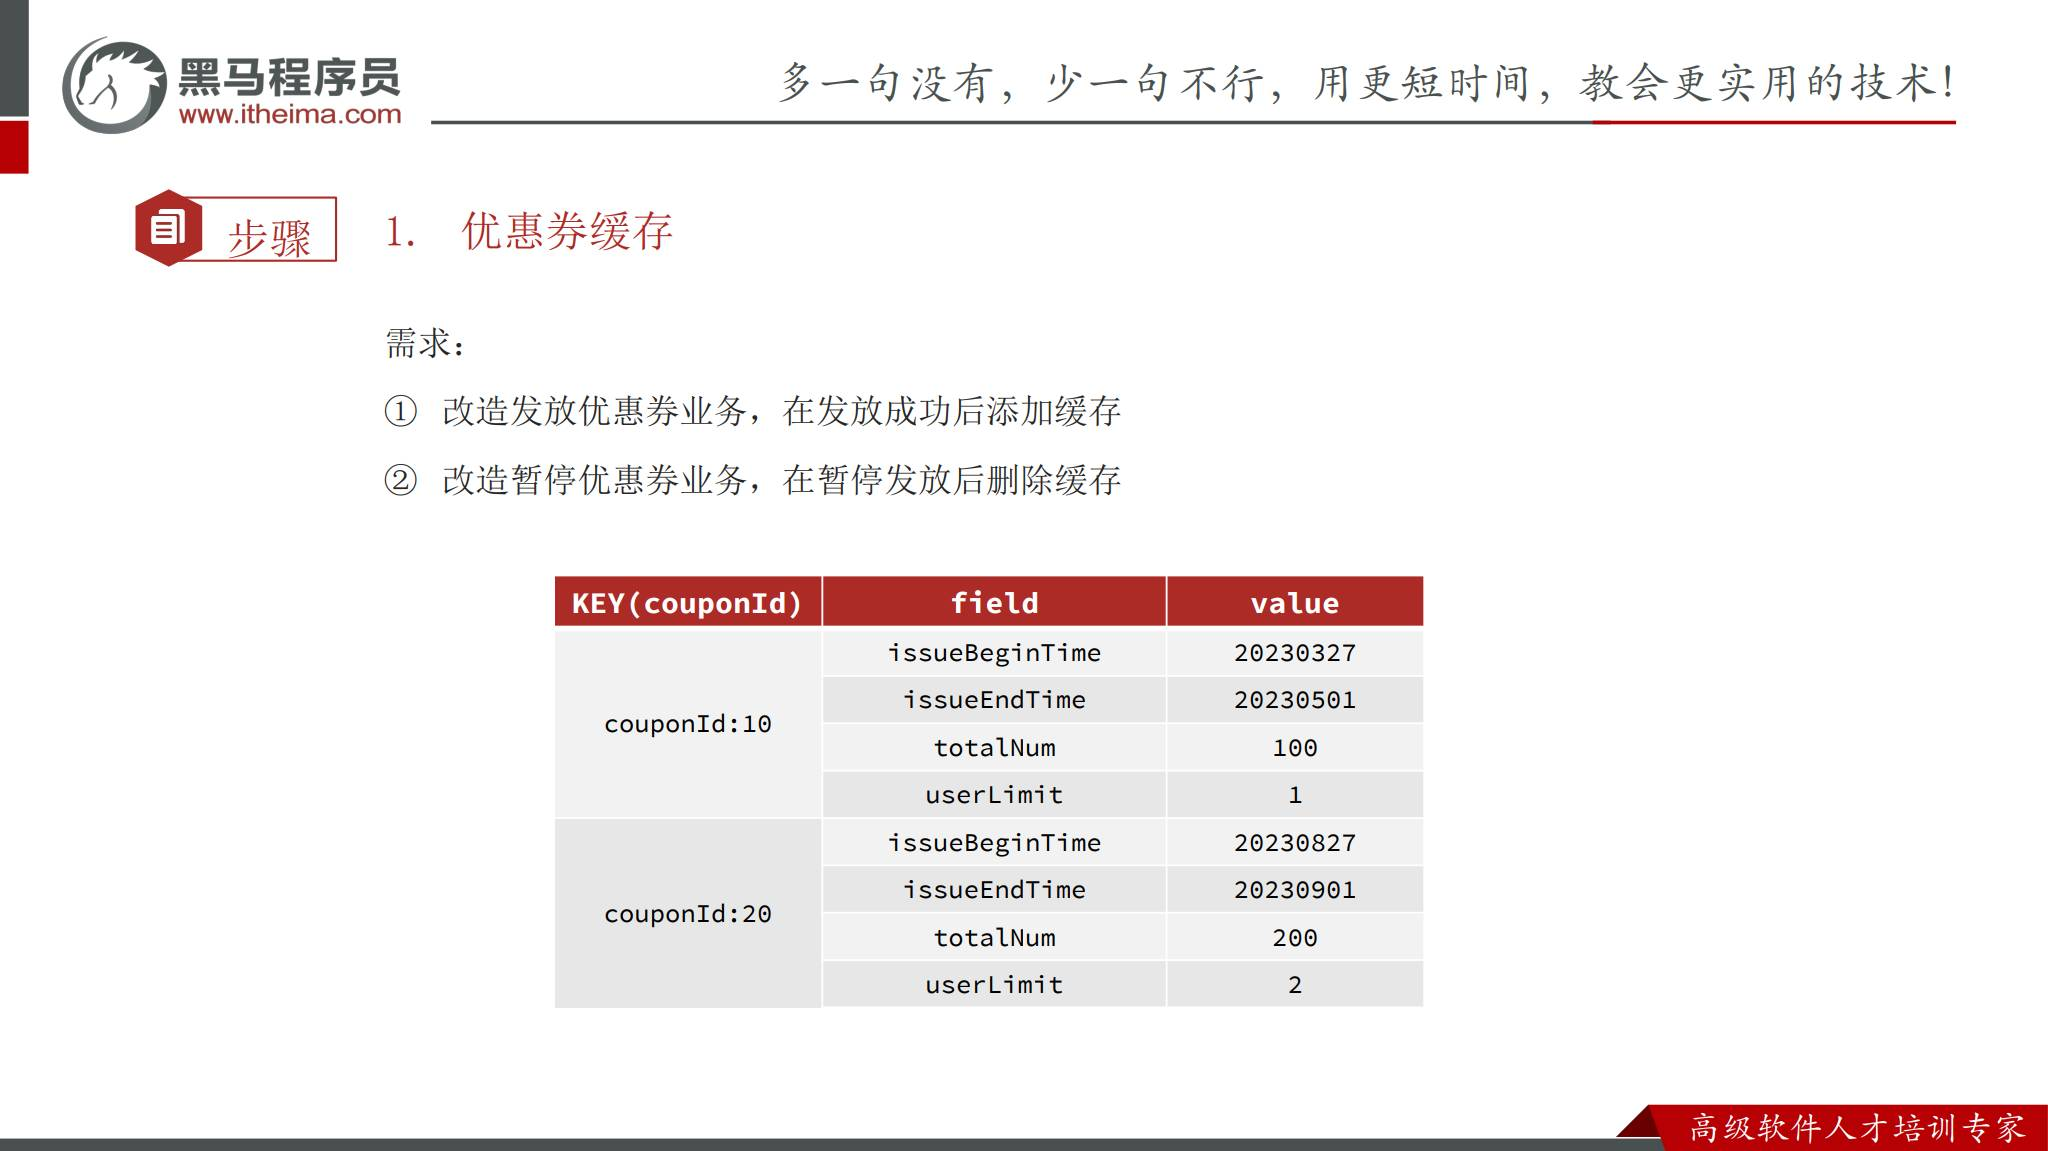

| Redis 数据 | 课件字段 | 含义 |
| --- | --- | --- |
| 券信息 Hash | `issueBeginTime`、`issueEndTime` | 发放起止时间 |
| 券信息 Hash | `totalNum` | 缓存中会递减，实际上是剩余可预占数 |
| 券信息 Hash | `userLimit` | 每人累计限领数 |
| 每张券的用户计数 Hash | field=userId，value=count | 累计已提交 + 已受理未入库的领取次数 |

DB 的 `total_num` 是总发行量；缓存的同名字段会被扣减，不能把二者混用。本文改进示例统一改名为 `stock`，并继续保留课件字段名说明。

课件键前缀为 `prs:coupon:` 与 `prs:user:coupon:`。Redis Cluster 改进示例使用 `prs:coupon:{1001}`、`prs:user:coupon:{1001}`；相同 `{1001}` hash tag 让两个 key 落在同一槽，便于执行 Lua。

图中 `20230327` 是日期示意，不能直接当作 Unix 时间戳；实际序列化和脚本必须统一单位。

## 发放、暂停和到期的缓存生命周期

**课件方案**在 `beginIssue()` 立即发放时写缓存；延时发放先设 `UN_ISSUE`，由定时任务到时间后设 `ISSUING` 并写缓存；`pauseIssue()` 设 `PAUSE` 并删除券信息 Hash；到期设 `FINISHED` 并清缓存。

| 状态变化 | 缓存操作 | 要核对的边界 |
| --- | --- | --- |
| 首次立即发放 | 初始化资格数据 | 从成功提交的模板创建，不开放未提交数据 |
| 定时开始发放 | 同步创建资格缓存 | 条件状态转换、重复任务幂等 |
| 暂停 | 关闭或删除资格入口 | 与并发 Lua 预占串行协调 |
| 恢复发放 | 恢复入口，保留正确余量与用户计数 | 不能重置为全发行量 |
| 到期结束 | 关闭入口，延后清理必要状态 | 已受理的消息是否继续完成须有业务契约 |

**补充 / 改进示例**：MySQL 事务不会回滚 Redis。事务提交后事件、可靠事件表与重试可同步状态；仅一个 `afterCommit` 回调仍可能在回调执行前宕机。活动状态切换宜使用版本号，避免旧任务重新开放已暂停的活动。

暂停用于拦截新请求，不等于可随意丢弃已受理消息。要定义“暂停前的资格继续兑现”还是“统一撤销并补偿”，而不是让消费时间决定用户结果。

## 恢复缓存不能把总量当成剩余量

转载缓存示例把 `coupon.getTotalNum()` 直接写入缓存 `totalNum`。首次发放时成立；发了 40 张、还有 10 张排队时暂停恢复，若重新写 100，会把库存放大。

```text
总发行量 100 = 数据库已发 40 + 已预占待提交 10 + 剩余可预占 50
```

只有没有并发预占、队列已清空时，才能按 `total_num - issue_num` 重建剩余量。有待提交请求时，还要减掉它们；数据库回写延迟期间不能用陈旧 `issue_num` 覆盖实时缓存。

**补充 / 改进示例**：暂停时保留库存、用户累计数与预占记录，只关闭 `active` 标志；恢复时改标志与发放窗口。若必须删缓存，则先阻止新预占、对账未完成记录、按版本原子恢复。

用户累计数也不能在暂停时清零，否则原用户能重新领满；TTL 应覆盖活动与补偿保留期。资格缓存是写路径状态，丢失后应关闭领取并修复，不能像普通展示缓存那样随便回源重置。

## Java 多命令校验版：为什么要按券加锁

**课件方案**的过渡流程如下：

```text
拿券锁 -> 读取缓存 -> 校验发放时间 -> 校验剩余量
       -> HINCRBY 用户次数 +1 -> 校验 userLimit
       -> HINCRBY totalNum -1 -> 发送 MQ -> 释放锁
```

`HINCRBY` 单条命令原子，不代表上述整段原子。若不同用户仅拿各自的锁，可能同时发现余量为 1，再各扣 1。

此外，转载把局部 Hash 映射为 `Coupon` 后仍使用 `issueNum >= totalNum`：缓存根本未保存 `issueNum`，会依赖实体默认值甚至出现空值问题。应该直接对剩余量做 `stock > 0` 判断，用明确的缓存 DTO 或读取 Hash 字段。

```java
Map<Object, Object> data = redisTemplate.opsForHash().entries(couponKey);
if (data.isEmpty()) throw new BizIllegalException("活动未开放");
long stock = Long.parseLong(data.get("totalNum").toString()); // 课件缓存名
if (stock <= 0) throw new BizIllegalException("库存不足");
```

多命令版本还要处理：超限时回退用户自增；MQ 发布失败时处理预占；暂停/重建使用同一协调协议。这里的事务注解不能替代 Redis 补偿。Lua 版将“先判断，再写入”放到同一脚本，避免超限请求留下次数。

## MQ 规范与 UserCouponDTO

原课件第 31 页的通信约定：

| 项目 | 值 |
| --- | --- |
| Exchange | `promotion.topic` |
| 类型 | topic |
| Routing Key | `coupon:receive` |
| 转载监听队列 | `coupon.receive.queue`，持久队列 |
| 手动领券消息 | `userId: Long`、`couponId: Long` |
| 兑换码练习增加 | `serialNum`，用于消费时更新兑换码 |

引入 `spring-boot-starter-amqp`，复用项目 `RabbitMqHelper`、`MqConstants.Exchange.PROMOTION_EXCHANGE` 与 `MqConstants.Key.COUPON_RECEIVE`。Broker 配置来自项目配置中心，不写在业务方法里。

```java
UserCouponDTO dto = new UserCouponDTO();
dto.setUserId(userId);
dto.setCouponId(couponId);
mqHelper.send(PROMOTION_EXCHANGE, COUPON_RECEIVE, dto);
```

**补充 / 改进示例**：消息还应携带稳定 `requestId`（预占与消费幂等键）、`acceptedAt`（受理时间）、`issueVersion`（发放配置版本）。兑换序列号全链路用 `Long`，避免第 09 章 32 位序号强转 `Integer` 的溢出问题。这些字段是新增设计，不是课前 DTO 已读出的字段。

## 监听器与数据库事务的职责

Redis 已经处理在线资格判断，消费者负责兑现资格，仍需事务保护持久化不变量。监听器只接收参数、调用独立服务，不在异步线程读取 HTTP 的 `UserContext`。

**整理示例**：

```java
@RabbitListener(bindings = @QueueBinding(
    value = @Queue(name = "coupon.receive.queue", durable = "true"),
    exchange = @Exchange(name = "promotion.topic", type = ExchangeTypes.TOPIC),
    key = "coupon:receive"))
public void onReceive(UserCouponDTO dto) {
    userCouponService.checkAndCreateUserCoupon(dto);
}
```

```sql
UPDATE coupon
SET issue_num = issue_num + 1
WHERE id = #{couponId}
  AND issue_num < total_num;
```

服务事务依次完成：查询对应模板及受理版本 → 条件更新发行量，影响行数必须为 1 → 新增用户券 → 如有序列号，条件更新兑换码。任一步失败抛出异常，整体回滚；监听异常交给重试策略，不能捕获后假装消费成功。

课件不再在消费者中重复统计每人限领，因为 Redis 已包含未入库的预占。移除这把业务锁不等于保证重复 MQ 不发券，消息幂等需要单独实现。

## 用户券有效期以哪个时点计算

异步消费可能晚于用户受理几分钟。按消费时间 `now()` 计算固定天数会让同一规则因队列延迟产生差异。

| 有效期类型 | 创建用户券时使用的值 |
| --- | --- |
| 模板固定起止时间 | 受理时确定的模板版本中的 `termBeginTime`、`termEndTime` |
| 自领取日起 N 天 | 根据业务定义，以 `acceptedAt` 作为领取时点，结束时间加 `termDays` |

**课件方案**复用 `saveUserCoupon()`，固定天数用执行时的当前时间。**补充 / 改进示例**在消息或预占记录中保存受理时间和配置版本，消费重试不能重新漂移有效期。

同时，消费者使用消息的 `userId`，状态设为未使用，ID 按项目雪花算法生成。若受理成功后活动暂停或到期，依照“已受理是否兑现”的规则处理，不要机械地重新检查消费时的发放窗口而误拒合法请求。

## 至少一次投递需要消费幂等

消费者提交数据库成功但 ACK 丢失，MQ 会再次投递。若每次都自增 `issue_num` 并新增用户券，就会重复发券。

不能对 `(user_id, coupon_id)` 永久唯一：课程允许 `userLimit > 1`。应使用“每次领取请求唯一”的标识。

**补充 / 改进示例**：为消费记录增加唯一主键 `request_id`，将登记记录、库存更新、用户券插入放入同一事务。

```sql
CREATE TABLE coupon_receive_dedup (
    request_id VARCHAR(64) CHARACTER SET ascii COLLATE ascii_bin PRIMARY KEY,
    user_id BIGINT NOT NULL,
    coupon_id BIGINT NOT NULL,
    accepted_at DATETIME(3) NOT NULL,
    created_at DATETIME(3) NOT NULL DEFAULT CURRENT_TIMESTAMP(3)
);
```

```text
开启事务 -> INSERT request_id（唯一约束）
         -> 条件增加 issue_num -> 插入用户券 -> 更新兑换码 -> 提交
```

重复键要核对 userId / couponId 是否与原请求一致，再判定已处理；仅捕获该登记语句的重复主键异常，不能吞掉后续用户券或兑换码的重复异常。更保守的处理是在事务外识别登记冲突并查询原结果；并发失败重试后，由数据库唯一约束决定只执行一次。

先扣库存再发现重复并正常返回，会把重复请求的扣减提交；幂等判断必须在副作用之前，或让整个重复事务回滚。

## MQ 发布、补偿与最终一致性

Lua 预占成功后、消息发布前宕机，Redis 留下资格但没有用户券。消息已进 Broker、发送端超时后又归还资格，则可能在旧消息兑现时超发。

| 故障 | 错误做法 | 合理处理 |
| --- | --- | --- |
| 明确未发布 | 什么都不处理 | 按 requestId 原子归还预占，或可靠重发 |
| 发布结果未知 | `catch` 后无条件归还 | 查发布状态、继续同 requestId 重发，不能猜失败 |
| 消费临时失败 | 吞异常后 ACK | 有界重试，保持资格占用 |
| 消费永久失败 | 无限重试或遗忘 | 死信、告警、业务终止状态及幂等补偿 |
| 提交成功 ACK 失败 | 再次新增用户券 | 消费去重并返回原结果 |

**补充 / 改进示例**：预占记录有 `RESERVED → PUBLISHED → COMMITTED`，终止则 `RELEASED`。只有已确认终止且未兑现的请求能归还一次；状态转换、计数恢复必须原子且幂等。

Publisher Confirm 确认 Broker 接收，mandatory/return 检查路由；持久队列、持久消息、消费者 ACK 各解决不同阶段问题。数据库 Outbox 能保证“数据库提交与待发事件同事务”，但单纯增加一张 Outbox 表并不能原子连接此前 Redis 预占；还要可靠记录预占与待发事件，或采用 Redis 内同脚本写可靠 Stream，再由转发器投递 RabbitMQ。

Redis 丢失、消息重复和恢复重建仍需 requestId、对账与重放协议。Lua、Redisson、MQ 任一组件都不能单独让三种存储成为一个事务。

## 接口成功应区分受理与最终发券

**课件方案**资格校验通过、发送 MQ 后返回成功，数据库稍后落库。消费失败或延迟仍可能发生，因此“已受理”比“已经可使用”更准确。

**补充 / 改进示例**可返回 requestId，提供 `PROCESSING / SUCCEEDED / FAILED` 查询结果，前端短轮询或通知刷新；返回 HTTP 202 是一种设计选项，需要同步修改接口契约，不是原课件已有接口。

展示列表也要注意：MySQL 的 `issue_num`、`user_coupon` 尚未更新，页面可能仍显示可领。最终领取以 Redis 原子资格判断为准；若页面要实时反馈，可结合预占状态。不能为了展示新鲜度，把查询列表结果当作领取授权。

监控既看 HTTP 受理数量，也看数据库成功发券量、消费失败量、队列积压和预占等待时间，否则接口很快但用户迟迟拿不到券，压测会产生虚假的“性能提升”。

## 兑换码异步领取的完整流程

兑换码在第 09 章由序列号生成，第 10 章用 Bitmap 判断是否已经兑换。本章练习把兑换资格校验放到 Redis，复用领券 MQ 消费者。

**课件方案**：

```text
解析并校验 code -> SETBIT 占用并检查旧值
               -> ZSet 查所属 couponId -> 读取券缓存
               -> 校验发放时间与用户累计限领
               -> 消息增加 serialNum -> 消费者事务生成用户券并更新兑换码
```

生成兑换码后向 `COUPON_RANGE_KEY` 写入：member 为 couponId，score 为该批次最大序列号。失败恢复 bitmap 是过渡版处理，不意味着 Redis 和 MQ 已原子。

**补充 / 改进示例**：先校验序号、映射、活动和限领，所有条件通过后才标记与计数；用 requestId 记录本次持有者，避免发送结果未知时随意清 bit。Bitmap 的 1 在异步链路中实际表示“已占用或已兑”，只有一位不能表达待处理、成功、失败，需要额外状态记录。

手动与兑换两种入口若共享同模板库存或用户额度，必须遵循同一计数和原子协议；只在其中一个入口加锁不能保护另一个入口的修改。

## ZSet 区间查找的成立条件

递增序号按批次连续分配，且每张券只有一个不重叠区间时，查第一个最大序号不小于 s 的区间，就能定位候选券。

| 券 | 分配范围 | ZSet score |
| --- | --- | --- |
| A | 1～5000 | 5000 |
| B | 5001～7000 | 7000 |
| C | 7001～10000 | 10000 |

课件使用 `ZRANGEBYSCORE range s (s+5000) LIMIT 0 1`，5000 来自每券发放上限。候选区间只有上界，不是独立的存在性证明：失败批次造成空洞、删除范围、起始序号无效时，可能误落到后一个区间。

**补充 / 改进示例**查询 `[s, +inf]` 第一个候选，并验证 `minSerial <= s <= maxSerial`、对应已生成记录/可信发行范围。追加发码时，member 仅用 couponId 会覆盖原 score，应按发行批次存区间。SQL 记录仍作为最终兑现依据。

4 字节无符号序列号范围可达 `2^32-1`；用 `long` / `Long` 和兼容的数据库列。ZSet score 使用双精度，32 位整数可精确表示，但不应把任意 64 位 Snowflake ID 放进 score 并依赖精确顺序。couponId 放 member 的十进制字符串即可。

## 消费兑换消息时用数据库状态条件兜底

Redis Bitmap 防止在线重复占用，数据库兑换记录负责最终归属。应使用“仍未兑换”的条件更新，而不是只按 ID 覆盖状态。

**补充 / 改进示例**，枚举实际值沿用项目定义：

```java
boolean updated = codeService.lambdaUpdate()
        .set(ExchangeCode::getUserId, dto.getUserId())
        .set(ExchangeCode::getStatus, ExchangeCodeStatus.USED)
        .eq(ExchangeCode::getId, dto.getSerialNum())
        .eq(ExchangeCode::getStatus, expectedUnusedStatus) // 使用项目未兑换枚举
        .eq(ExchangeCode::getExchangeTargetId, dto.getCouponId())
        .update();
if (!updated) throw new BizIllegalException("兑换码状态冲突");
```

先按 requestId 判断本消息是否已成功处理；若是则直接返回原结果。新的冲突消息影响行数为 0 时，让库存与新增用户券同事务回滚，不能“更新码失败但用户券已生效”。

转载中 `if (serialNum != null)` 的未声明变量应改为 `dto.getSerialNum()`；DTO 改成 Long 后，消费者、Mapper、数据库与生成工具都要同步兼容，不能只改消息类型。

## Lua 为什么能替代在线资格锁

多命令 Redis 校验仍要取锁并多次往返。Lua 将存在性、时间、库存、用户累计数和预占写入放到 Redis 内执行；一次脚本期间其他命令不能插入这些步骤，因此无需再对同一临界区加客户端分布式锁。

| 方案 | 往返与互斥方式 | 能覆盖的范围 |
| --- | --- | --- |
| Java 多命令 + Redisson | 多次请求，客户端持有锁 | 遵循同锁协议的业务代码 |
| Redis pipeline | 批量减少往返 | 本身不保证读判断写的隔离 |
| Redis `MULTI/EXEC` | 事务命令序列 | 不能在排队期间读取结果再做 Lua 式条件分支 |
| Lua | 一次调用、脚本内无其他客户端命令穿插 | 当前节点同槽 Redis 数据 |

> Lua 的“原子”是执行时不被其他命令插入，不是数据库式回滚。脚本先写后报错，已经写入的变化不会自动撤销；`redis.pcall` 也不会把之前写入回滚。

所以先做数据类型和数值校验，再执行写入；保证脚本短、没有无界遍历。Lua 运行期间占用 Redis 执行线程，长脚本会拖慢其他业务。

## Lua 基础、KEYS / ARGV 与 EVAL

本章只需要 Lua 的变量、条件、表和 Redis 调用。Redis 经典脚本环境基于 Lua 5.1，不能假设 Lua 5.4 教程中的所有语法都可用。

```lua
local stock = tonumber(redis.call('HGET', KEYS[1], 'stock'))
if stock == nil then
    return 5
elseif stock <= 0 then
    return 2
end
return 0
```

| 语法 | 含义 |
| --- | --- |
| `local x` | 局部变量 |
| `tonumber(x)` | 字符串转数字，失败为 nil |
| `..` | 拼接字符串 |
| `~=`, `==` | 不等、相等 |
| `KEYS[1]` / `ARGV[1]` | Lua 下标从 1 开始；键与普通参数分开 |
| `redis.call()` | 执行 Redis 命令，错误会中断脚本 |
| `return` | 把结果交给 Java / CLI |

```text
EVAL "return redis.call('SET', KEYS[1], ARGV[1])" 1 demo:name Rose
```

`1` 是 key 数量，其后一个参数进入 KEYS，剩余进入 ARGV。实际工程保存 `.lua` 文件，使用脚本 SHA 缓存；脚本缓存丢失时要处理 `NOSCRIPT`。Redis 脚本不能连接 RabbitMQ 或数据库，也不适合做外部网络调用。

## 课件领券脚本与需要修正的边界

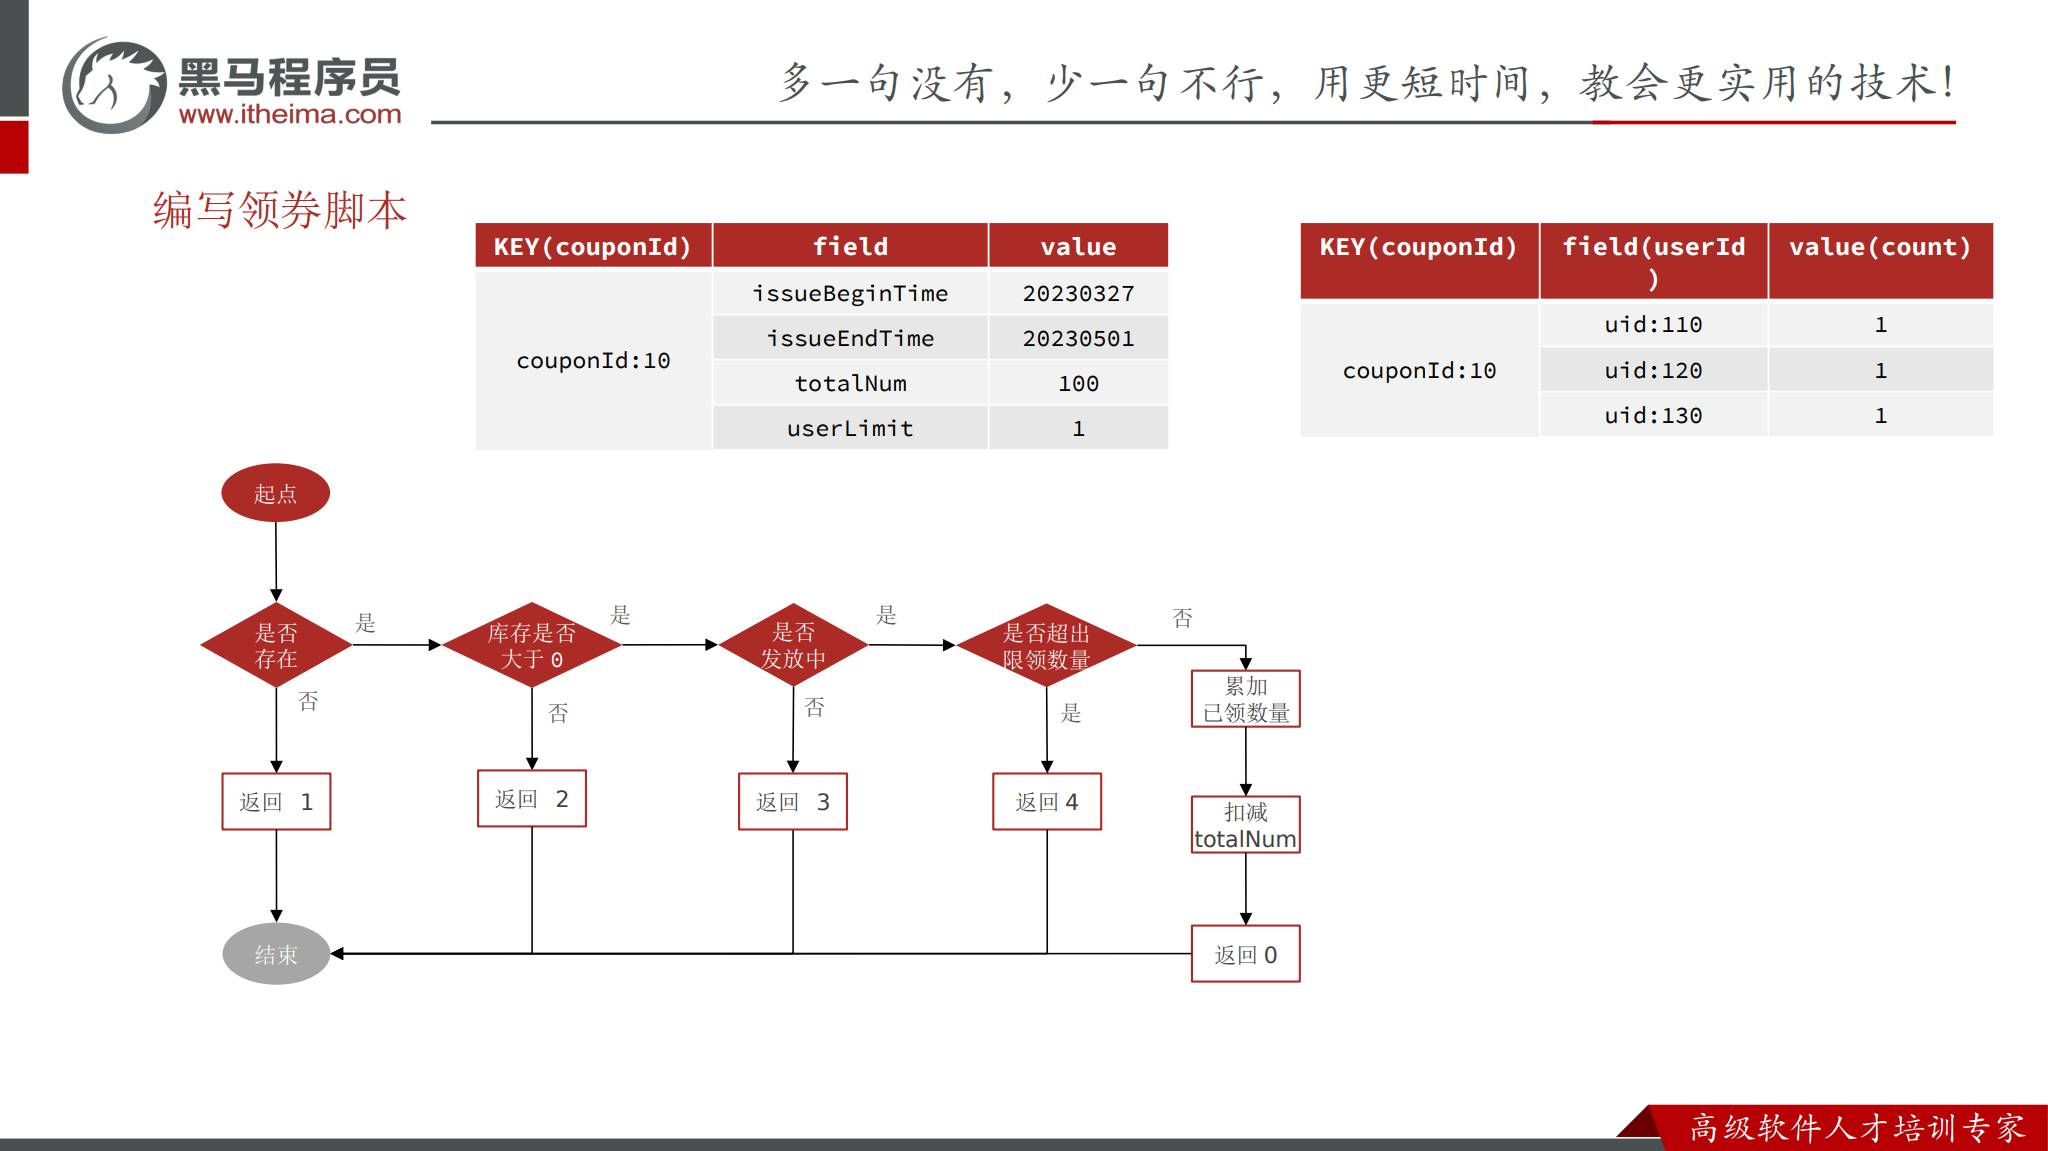

**课件方案**返回码：`0` 成功、`1` 缓存不存在、`2` 库存不足、`3` 已结束、`4` 超限。第 45 页关键逻辑是：

```lua
if tonumber(redis.call('HGET', KEYS[1], 'userLimit'))
        < redis.call('HINCRBY', KEYS[2], ARGV[1], 1) then
    return 4
end
redis.call('HINCRBY', KEYS[1], 'totalNum', -1)
return 0
```

| 问题 | 后果 | 改进方向 |
| --- | --- | --- |
| 超限前先 HINCRBY，超限后直接返回 | 失败请求也增加次数；后续补偿口径不正确 | 先 HGET 判断，通过后再递增 |
| 缓存时间写 epoch 毫秒，脚本 `TIME[1]` 是秒 | 到期判断可能永不成立 | 全部按毫秒，或全部按秒 |
| 只比较结束时间 | 错误提前建缓存可被提前领取 | 同时检查开始和结束 |
| 字段缺失 / 错误类型 | tonumber 得到 nil 或命令错误 | 写入前校验，失败关闭领取 |
| 结果 null 被转为 0 | 调用无有效结果却被当作成功 | null 作为系统异常 |

本文改进示例采用半开窗口 `[begin, end)`：开始瞬间可领，到结束瞬间停止。原课件的 `now > end` 包含结束点，实际工程要统一数据库、Java 与 Lua 的边界定义。

## 改进领券脚本：所有判断通过才写入

**补充 / 改进示例**：缓存改用 `stock`，时间均为 epoch 毫秒。KEYS 是同券同槽的两个 Hash；ARGV[1] 是已认证 userId 的字符串。本片段只负责一次新请求资格预占，requestId 重试幂等在后文补充。

```lua
-- 0 成功；1 未开放；2 库存不足；3 不在时间窗口；4 超限；5 数据异常
local t1 = redis.call('TYPE', KEYS[1]).ok
local t2 = redis.call('TYPE', KEYS[2]).ok
if t1 == 'none' then return 1 end
if t1 ~= 'hash' or (t2 ~= 'none' and t2 ~= 'hash') then return 5 end
if ARGV[1] == nil or ARGV[1] == '' then return 5 end

local fields = redis.call('HMGET', KEYS[1],
    'issueBeginTime', 'issueEndTime', 'stock', 'userLimit')
local beginMs = tonumber(fields[1])
local endMs = tonumber(fields[2])
local stock = tonumber(fields[3])
local limit = tonumber(fields[4])
local rawCount = redis.call('HGET', KEYS[2], ARGV[1])
local count = rawCount and tonumber(rawCount) or 0
-- 用规范整数文本存储计数，避免 HINCRBY 在写入后才发现坏数据
if not beginMs or not endMs or not stock or not limit then return 5 end
local function canonicalUnsigned(s)
    return s == '0' or (s and string.match(s, '^[1-9]%d*$') ~= nil)
end
if not canonicalUnsigned(fields[3]) or not canonicalUnsigned(fields[4]) then return 5 end
if rawCount and not canonicalUnsigned(rawCount) then return 5 end
if endMs <= beginMs or limit < 1 or stock < 0 or count < 0 then return 5 end
-- 课程每券总量不超过 5000，限制数值范围也避免溢出
if stock > 5000 or limit > 5000 or count > 5000 then return 5 end

local tm = redis.call('TIME')
local nowMs = tonumber(tm[1]) * 1000 + math.floor(tonumber(tm[2]) / 1000)
if nowMs < beginMs or nowMs >= endMs then return 3 end
if stock <= 0 then return 2 end
if count >= limit then return 4 end

redis.call('HINCRBY', KEYS[1], 'stock', -1)
redis.call('HINCRBY', KEYS[2], ARGV[1], 1)
return 0
```

失败不会更改库存或次数；成功才同时扣余量、占用户额度。数据类型及业务条件先全部检查，减少运行时错误留下部分写入的风险；Redis 内存不足等基础设施故障仍须按结果未知处理和对账，Lua 并非可回滚事务。

这段不是网盘附件原文；活动控制、requestId、消息可靠记录要作为同一协议继续扩展。

## Spring Data Redis 加载脚本和检查返回值

**整理示例**按课件目录把脚本放在 `resources/lua/receive_coupon.lua`；以下调用使用前文改进的 stock / 毫秒契约。

```java
private static final RedisScript<Long> RECEIVE_SCRIPT = RedisScript.of(
        new ClassPathResource("lua/receive_coupon.lua"), Long.class);

public void receiveCoupon(Long couponId) {
    Long userId = UserContext.getUser();
    if (userId == null) throw new BizIllegalException("请先登录");
    String tag = "{" + couponId + "}";
    Long result = redisTemplate.execute(RECEIVE_SCRIPT,
            Arrays.asList("prs:coupon:" + tag, "prs:user:coupon:" + tag),
            userId.toString());
    if (result == null) throw new IllegalStateException("Redis 未返回领取结果");
    if (result != 0L) {
        throw new BizIllegalException(errorMessage(result));
    }
    // 此处转入可靠发布协议；不能把 Lua 成功与 RabbitMQ 发送当成一个事务
}
```

`errorMessage` 用显式 switch 映射 1～5；未知返回值报系统错误，不能直接 `ERRORS[result-1]` 越界。Spring 的脚本执行器会处理脚本序列化、结果类型，通常先 EVALSHA 再按需要 EVAL，具体行为依版本确认。

脚本资格通过只能说明 Redis 已预占；若连接超时可能“执行了但响应丢失”，盲目再次执行本脚本会再次占用。这需要稳定 requestId 与状态查询，而不是只在 Java catch 中重试。

## Lua 兑换脚本的结果和原子范围

**课件方案**兑换脚本先 `GETBIT`，用 `ZRANGEBYSCORE` 找 couponId，动态构造券与用户 Hash 键，检查结束时间与用户限领，再 `SETBIT`，成功返回 couponId 字符串。Java 把小于 10 的返回值当错误码。

| 课件返回字符串 | 含义 |
| --- | --- |
| `"1"` | 已兑换或已占用 |
| `"2"` | 未找到兑换序号对应区间 |
| `"3"` | 券资格缓存不存在 |
| `"4"` | 发放已结束 |
| `"5"` | 用户超过限领 |
| couponId 字符串 | 校验通过，发送包含此 ID 和 serialNum 的消息 |

这个契约依赖 couponId 大于错误码，且有如下边界：

| 需要改进 | 具体原因 |
| --- | --- |
| 明确成功与错误返回类型 | 返回 `{"OK", couponId}` 或 `{"ERR", code}`，避免 ID 与错误码冲突 |
| 检查序号完整范围 | 负数、空洞、错误批次不能仅靠上界映射 |
| 校验开始与结束、统一单位 | 与手动领取采用相同时间窗口 |
| 超限失败不写计数 | 先检查已领数，全部通过后写入 |
| 同模板共享库存时同样扣减 | 课件兑换版没有扣余量，只依赖每码唯一；不能推广到混合领取方式 |
| 补全 requestId 状态 | Bitmap 只有一位，无法表达具体请求归属与终态 |

动态在 Lua 里拼出未显式传入 KEYS 的 key，在 Redis Cluster 中尤其有问题。生产可先可信解析到 couponId / 批次，再把所有同槽键显式传入；脚本检查映射仍然一致。返回 couponId 必须保留字符串，别 `tonumber` 转 64 位 ID 后丢精度。

**补充 / 改进示例**：同槽、合法序号、活动时间、余量和用户额度全部验证后，再在脚本末尾写入；失败分支放在这些写入之前。

```lua
-- KEYS[1] 券 Hash；KEYS[2] 用户 Hash；KEYS[3] 券/批次 Bitmap
-- ARGV[1] userId；ARGV[2] 已校验的批次内 bit offset；ARGV[3] couponId 字符串
-- 前置校验 GETBIT == 0、有效序号、活动窗口、stock > 0、count < userLimit
redis.call('HINCRBY', KEYS[1], 'stock', -1)
redis.call('HINCRBY', KEYS[2], ARGV[1], 1)
redis.call('SETBIT', KEYS[3], ARGV[2], 1)
return {'OK', ARGV[3]}
```

这是尾部片段而非完整可执行脚本；也要预检所有 key 类型和 offset 范围。Java 以 `List` 接收结构化结果，失败统一返回 `{'ERR', '错误码'}`，不再通过 couponId 的大小区分成功。

## Redis Cluster 下的同槽与全局 Bitmap

单 Redis 示例可以一次脚本访问多个普通 key；Redis Cluster 多键脚本要求键位于同一槽。仅把参数名叫 KEYS 不会让任意 key 自动同槽。

```text
prs:coupon:{1001}
prs:user:coupon:{1001}
prs:request:{1001}:request-abc
prs:code-bitmap:{1001}:batch-2
```

相同 hash tag 把同券关键数据组织到一槽。课件的全局 `COUPON_CODE_MAP_KEY` 与全局 `COUPON_RANGE_KEY` 无法天然和每券 Hash 保持同槽：可按券/发行批次拆 Bitmap，映射查找前置，再在脚本中验证；或设计分区级统一 tag，但会带来热点。不能简单把全部业务塞一个 tag 并声称已水平扩容。

如果数据库侧也要保障额度，可增加 `(user_id, coupon_id)` 唯一的累计额度行，条件增加 `received_count`，在事务中与用户券入库一起维护。该唯一约束针对计数行，不是限制用户券只能有一张；它是第 10 章额度计数方案的延伸。

## 请求重试、对账与预占恢复

消费幂等只防 MQ 重复，无法防止同一个 HTTP 请求在 Redis 多占一次；预占阶段也需要幂等。

**补充 / 改进示例**：同槽存放 requestId 对应的 userId、couponId、受理版本和状态。脚本先查请求记录：已存在且参数相同就返回原结果，未存在才扣库存、占额度并记录。不同参数复用同 requestId 应拒绝。

对账以数据库已兑现记录和可靠预占记录为依据：

```text
可继续预占的余量 = 本批次总量 - 已兑现量 - 活跃未兑现预占量
用户占用次数     = 用户累计已兑现次数 + 用户活跃未兑现预占次数
```

只有成功进入 `RELEASED` 的终止预占才归还一次，`COMMITTED` 重试不得归还；未知提交结果先查数据库。补偿保留期、请求去重保留期必须覆盖消息可能的重放时间；不能让 requestId 记录过期但旧消息仍可重投。

Redis 和 DB 对账差异不应直接用“DB 数量覆盖缓存”处理，因为 DB 可能落后。先关闭或版本化活动、确认未完成请求，再恢复资格入口。

## 压测看吞吐，也看最终业务不变量

网盘有 `领取优惠券.jmx`，本章未取得全文、未运行。按课程思路使用前应核对 URL、登录 token、CSV 用户数据、请求总量和线程组，不能把第 10 章的端口或账号直接套用。

| 场景 | 必须观察的结果 |
| --- | --- |
| 多用户争抢最后一张 | Redis 余量不负，数据库只新增一张 |
| 同用户并发超过限领 | 累计成功 + 未兑现预占不超过上限 |
| 两个 promotion 实例 | 互斥与预占结果同单实例，不依赖 JVM 本机锁 |
| 重复消息 / HTTP 重试 | 同 requestId 至多兑现一次、至多预占一次 |
| 发布超时、消费失败、进程宕机 | 最终能兑现或明确失败且幂等归还，无无主预占 |
| 暂停恢复 / 到期 | 不重置库存或用户额度，受理边界明确 |

分别记录请求延迟、受理成功率、最终发券率、队列积压、消费耗时、数据库冲突和补偿次数。高吞吐但库存错误、消息积压持续增长都不能算优化成功。

实测步骤需要隔离测试数据；本笔记只给验证设计，不声称课程链路已跑通。

## 课后练习与实现范围

| 课程任务 | 实现重点 | 验收要点 |
| --- | --- | --- |
| 通用注解锁 | 注解、AOP、工厂、策略、SpEL | 锁在事务外，失败不执行业务，动态键正确 |
| 缓存发放生命周期 | 立即/定时发放、暂停、结束 | 状态同步可重试，恢复不重置余量 |
| 兑换码异步领取 | 生成范围缓存，Redis 校验，消息携带 serialNum | 编码所属区间正确，消费状态条件更新 |
| Lua 改进领取 | 一次校验并预占，Java 检查返回码 | 时间统一、超限无副作用、所有 key 同槽 |
| 工程补充 | 请求/消费幂等、发布确认、补偿、对账 | 重试不多发，未知结果不盲归还 |

最后一行是本文新增的工程设计，不是课件已完成实现。单独 Lua / Java / JMX 附件未取得正文，示例来自原 PPT、公开转载与明确标注的改进，不宣称与网盘附件逐字相同。

## 面试提示

**面试提示**：按“业务约束 → 集群互斥 → 性能 → 可靠性”回答。

1. **如何防超发？** 全局发行量用带库存条件的 SQL 更新，检查影响行数；用户累计限领通过锁覆盖校验和事务提交，或 Redis Lua 原子预占，二者是不同约束。
2. **为什么用 Redisson？** 本机锁无法跨 JVM；Redisson 提供重入、等待、自动续期与原子解锁。续期不等于故障时永不丢锁，数据库不变量仍需兜底。
3. **用过什么设计模式？** 工厂根据枚举创建锁类型，策略枚举选择等待与失败方式，注解 + AOP 抽取固定锁逻辑，SpEL 生成动态键。应按实际做过的工作陈述。
4. **高峰写入怎么优化？** Redis 校验并预占，MQ 控制消费者写库速度，Lua 减少网络往返。受理成功与最终入库分开观察。
5. **Lua 保证了什么？** 同节点执行期间无其他命令插入；不自动回滚已写内容，不覆盖 MQ 和 MySQL，Cluster 还要求同槽。
6. **重复投递和中途宕机怎么办？** 同 requestId 的预占与消费幂等，事务内保护入库，发布确认与可靠事件记录保证可重发，终止预占幂等补偿，未知结果查询和对账后再决策。